<a href="https://colab.research.google.com/github/bramhani007/192425319-MLA0204/blob/main/Practical_Problem_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving future_sales.csv to future_sales.csv
FUTURE SALES DATASET:
    Month  Advertising_Budget_Thousands  Product_Price  Previous_Month_Sales  \
0       1                            20            500                   450   
1       2                            22            500                   480   
2       3                            24            495                   500   
3       4                            25            495                   530   
4       5                            27            490                   560   
5       6                            28            490                   590   
6       7                            30            485                   610   
7       8                            32            485                   650   
8       9                            31            490                   680   
9      10                            35            480                   690   
10     11                            36            480

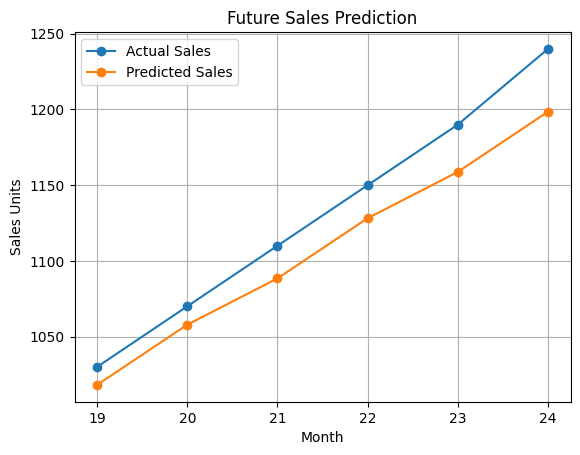

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io
from google.colab import files

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Upload dataset
uploaded = files.upload()
filename = next(iter(uploaded))

data = pd.read_csv(io.BytesIO(uploaded[filename]))

print("FUTURE SALES DATASET:")
print(data)

# Input features
X = data[[
    "Month",
    "Advertising_Budget_Thousands",
    "Product_Price",
    "Previous_Month_Sales"
]]

# Target variable
y = data["Sales"]

# Chronological split:
# First 18 months for training and last 6 for testing
X_train = X.iloc[:18]
X_test = X.iloc[18:]

y_train = y.iloc[:18]
y_test = y.iloc[18:]

# Create Linear Regression model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Predict future sales for test period
y_pred = model.predict(X_test)

# Display results
print("\nActual Sales:")
print(y_test.values)

print("\nPredicted Sales:")
print(np.round(y_pred, 2))

# Evaluation
print("\nMean Absolute Error:")
print(mean_absolute_error(y_test, y_pred))

print("\nMean Squared Error:")
print(mean_squared_error(y_test, y_pred))

print("\nRoot Mean Squared Error:")
print(np.sqrt(mean_squared_error(y_test, y_pred)))

print("\nR2 Score:")
print(r2_score(y_test, y_pred))

# Predict next month's sales
next_month = pd.DataFrame({
    "Month": [25],
    "Advertising_Budget_Thousands": [63],
    "Product_Price": [440],
    "Previous_Month_Sales": [1240]
})

future_prediction = model.predict(next_month)

print("\nFuture Sales Prediction:")
print("Predicted Sales for Month 25:")
print(round(future_prediction[0], 2), "Units")

# Plot actual vs predicted sales
plt.plot(
    X_test["Month"],
    y_test,
    marker="o",
    label="Actual Sales"
)

plt.plot(
    X_test["Month"],
    y_pred,
    marker="o",
    label="Predicted Sales"
)

plt.xlabel("Month")
plt.ylabel("Sales Units")

plt.title("Future Sales Prediction")

plt.legend()
plt.grid()
plt.show()